In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [2]:
df = pd.read_csv("deces.csv", 
     usecols=
        [
        'nom',
        'prenoms',
        'sexe',
        'date_naissance',
        'date_deces',
        'code_insee_deces',
        'opposition'
        ],
)
df = df[df['opposition'] == False]

/tmp/ipykernel_11010/2162075475.py:1: DtypeWarning: Columns (8) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("deces.csv",


In [3]:
df

,nom,prenoms,sexe,date_naissance,date_deces,code_insee_deces,opposition
0,RUMIANO,FERNANDO,M,19301001,20240113,01004,False
1,BONNET,YVONNE,F,19380514,20240103,01004,False
2,GEOFFRAY,RAYMONDE,F,19360408,20240124,01004,False
3,REISSER,"JEANNINE,HENRIETTE,EMILIE",F,19310315,20240112,01004,False
4,MAHIEU,"JEAN,RENE",M,19320430,20240124,01004,False
...,...,...,...,...,...,...,...
28389332,SARAMITTO,ROBERT,M,19350601,20250101,99326,False
28389333,HOUDEVILLE,"JEAN,LOUIS",M,19390929,20241224,99341,False
28389334,MOUBARAK,NATHALIE,F,19850808,20241223,99205,False
28389335,ITEN,"JEAN-JACQUES,JOSEPH",M,19571222,20241114,99109,False


In [4]:
df['date_naissance'] = pd.to_datetime(df['date_naissance'], format='%Y%m%d', errors='coerce')
df['date_deces'] = pd.to_datetime(df['date_deces'], format='%Y%m%d', errors='coerce')
df['code_insee_deces'] = pd.to_numeric(df['code_insee_deces'], errors='coerce')
df.drop_duplicates(inplace=True)

In [5]:
dupli = df.duplicated()

In [6]:
df[dupli]

,nom,prenoms,sexe,date_naissance,date_deces,code_insee_deces,opposition


In [7]:
np.unique(dupli.values, return_counts=True)

(array([False]), array([28174184]))

In [8]:
nans = df[df.isnull().any(axis=1)]

In [9]:
nans.to_csv("nans.csv")

In [10]:
all_deaths = df.groupby('date_deces').size().reset_index(name='count')
all_deaths = all_deaths[all_deaths['date_deces'].between('1974-01-01', '2024-12-31')]
all_deaths['year'] = pd.DatetimeIndex(all_deaths['date_deces']).year
all_deaths['month'] = pd.DatetimeIndex(all_deaths['date_deces']).month
all_deaths['day'] = pd.DatetimeIndex(all_deaths['date_deces']).day
all_deaths = all_deaths[~((all_deaths.month == 2) & (all_deaths.day == 29))]

all_deaths

,date_deces,count,year,month,day
4422,1974-01-01,1091,1974,1,1
4423,1974-01-02,1132,1974,1,2
4424,1974-01-03,1111,1974,1,3
4425,1974-01-04,1117,1974,1,4
4426,1974-01-05,1043,1974,1,5
...,...,...,...,...,...
23045,2024-12-27,2174,2024,12,27
23046,2024-12-28,2149,2024,12,28
23047,2024-12-29,2133,2024,12,29
23048,2024-12-30,2223,2024,12,30


In [11]:
all_deaths

,date_deces,count,year,month,day
4422,1974-01-01,1091,1974,1,1
4423,1974-01-02,1132,1974,1,2
4424,1974-01-03,1111,1974,1,3
4425,1974-01-04,1117,1974,1,4
4426,1974-01-05,1043,1974,1,5
...,...,...,...,...,...
23045,2024-12-27,2174,2024,12,27
23046,2024-12-28,2149,2024,12,28
23047,2024-12-29,2133,2024,12,29
23048,2024-12-30,2223,2024,12,30


month
1     40922
2     36688
3     41617
4     38259
5     37499
6     36039
7     36179
8     35962
9     35050
10    38581
11    38542
12    42105
Name: count, dtype: int64

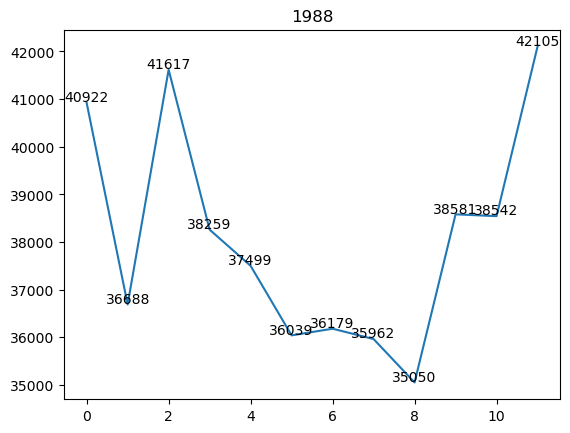

In [13]:
year = 1988
monthly = all_deaths.groupby(['year', 'month'])['count'].sum()

fig = plt.figure()
ax = fig.add_subplot(111)
plt.plot(monthly[year,:].values)

for i, v in enumerate(monthly[year,:].values):
    ax.text(i, v+30, "%d" %v, ha="center")
plt.title(year)
monthly[year,:]

In [13]:
monthly.reset_index()

,year,month,count
0,1974,1,32245
1,1974,2,28472
2,1974,3,32849
3,1974,4,30975
4,1974,5,31589
...,...,...,...
607,2024,8,50134
608,2024,9,50033
609,2024,10,56204
610,2024,11,53333


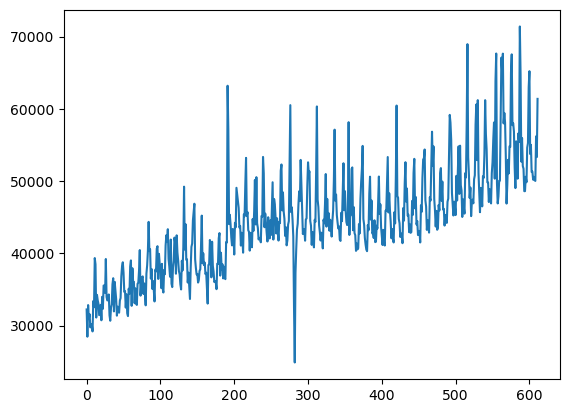

In [14]:
plt.plot(monthly.reset_index()['count'])

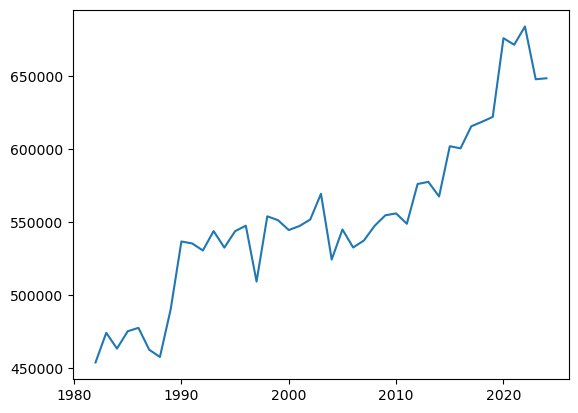

In [15]:
yearly = all_deaths['count'].groupby(all_deaths.year).sum()
plt.plot(yearly[8:])

In [16]:
yearly

year
1974    380804
1975    399572
1976    408008
1977    405033
1978    421364
1979    425398
1980    437129
1981    455043
1982    453666
1983    473990
1984    463191
1985    475069
1986    477407
1987    462424
1988    457443
1989    490073
1990    536605
1991    535273
1992    530445
1993    543746
1994    532414
1995    543670
1996    547428
1997    509159
1998    553866
1999    551196
2000    544467
2001    547226
2002    551664
2003    569306
2004    524223
2005    544840
2006    532490
2007    537295
2008    547369
2009    554583
2010    555852
2011    548760
2012    576015
2013    577494
2014    567453
2015    601919
2016    600474
2017    615563
2018    618672
2019    622023
2020    675954
2021    671489
2022    684007
2023    647829
2024    648494
Name: count, dtype: int64

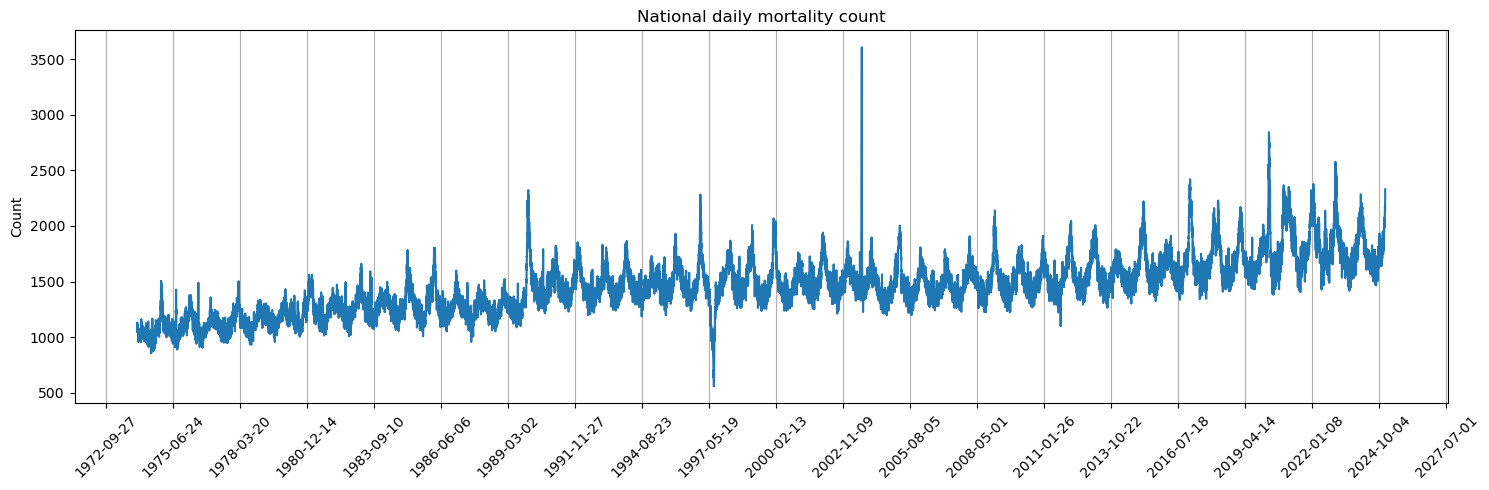

In [17]:
plt.figure(figsize=(15,5))
plt.plot(all_deaths['date_deces'], all_deaths['count'])
plt.grid(axis='x')
ax = plt.gca()
ax.xaxis.set_major_locator(plt.MaxNLocator(21))
plt.xticks(rotation=45)
plt.title("National daily mortality count")
plt.ylabel("Count")
plt.tight_layout()
plt.savefig("national_mort.png")
plt.show()


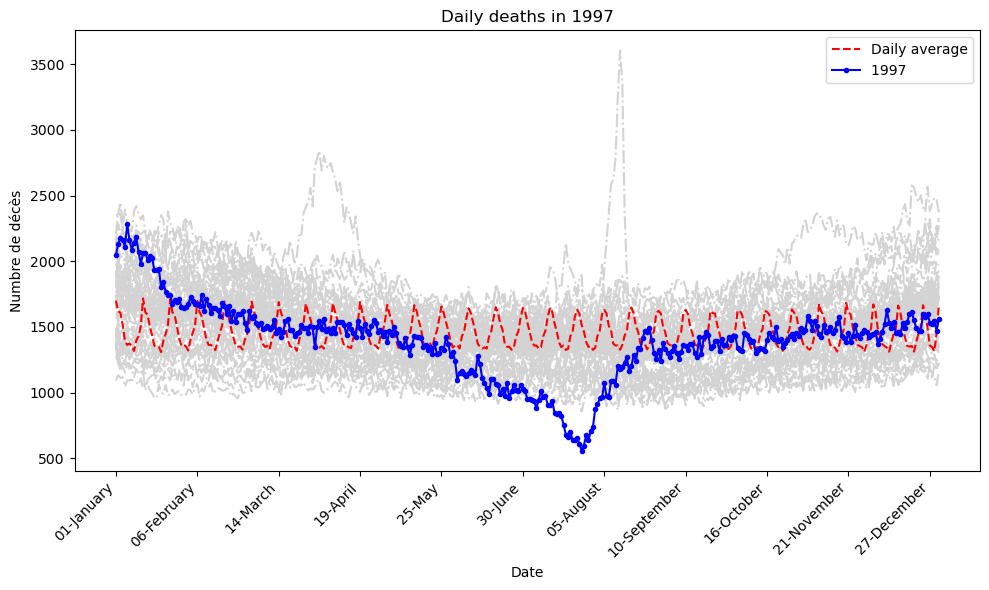

In [18]:
all_deaths_1997 = all_deaths[all_deaths['date_deces'].dt.year == 1997]
all_deaths_other_years = all_deaths[all_deaths['date_deces'].dt.year != 1997]
daily_mean = all_deaths_other_years.groupby(all_deaths_other_years['date_deces'].dt.date)['count'].mean()

all_deaths['day_month'] = all_deaths['date_deces'].dt.strftime('%d-%m')
daily_mean = all_deaths.groupby('day_month')['count'].mean()

plt.figure(figsize=(10, 6))
# Plot count for 1997

for year in np.unique(all_deaths['year']):
    tmp = all_deaths_other_years[all_deaths_other_years['year'] == year]
    plt.plot(tmp['date_deces'].dt.strftime('%d-%B'), tmp['count'], linestyle='-.', color='lightgrey')
# Plot daily mean count for other years
plt.plot(all_deaths_1997['date_deces'].dt.strftime('%d-%B'), daily_mean.values, label='Daily average', color='r', linestyle='--')
plt.plot(all_deaths_1997['date_deces'].dt.strftime('%d-%B'), all_deaths_1997['count'], marker='.', label='1997 ', color='b')

# Title and labels
plt.title('Daily deaths in 1997')
plt.xlabel('Date')
plt.ylabel('Numbre de décès')
plt.xticks(rotation=45, ha='right')  # Rotate and align the labels to the right
plt.xticks(ticks=range(0, len(all_deaths_1997), len(all_deaths_1997)//10)) 
plt.tight_layout()
plt.legend()
plt.savefig("all_deaths_1997.png")
plt.show()

In [19]:
invalid_count_n = df['date_naissance'].isna().sum()
invalid_count_d = df['date_deces'].isna().sum()
invalid_count_c = df['code_insee_deces'].isna().sum()
print(f'Invalid naissance: {invalid_count_n/len(df)*100:.3f}%')
print(f'Invalid deces: {invalid_count_d/len(df)*100:.3f}%')
print(f'Invalid code: {invalid_count_c/len(df)*100:.3f}%')

#df_pp = df.dropna(subset=['date_naissance', 'date_deces', 'code_insee_deces'])
df_pp = df.dropna(subset=['date_deces', 'code_insee_deces'])
df_pp['code_insee_deces'] = df_pp['code_insee_deces'].astype('int')
print(f"Lost rows {(1-len(df_pp)/len(df))*100:.3f}%")
df_pp = df_pp[df_pp['date_deces'].between('1974-01-01', '2024-12-31')]
df_pp = df_pp[df_pp['date_deces'].dt.month.isin([6, 7, 8])]
df_pp['age'] = (df_pp['date_deces'] - df_pp['date_naissance']).dt.days // 365


Invalid naissance: 0.386%
Invalid deces: 0.003%
Invalid code: 0.333%


/tmp/ipykernel_25469/1520631503.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_pp['code_insee_deces'] = df_pp['code_insee_deces'].astype('int')


Lost rows 0.336%


Text(0.5, 1.0, 'National mortality')

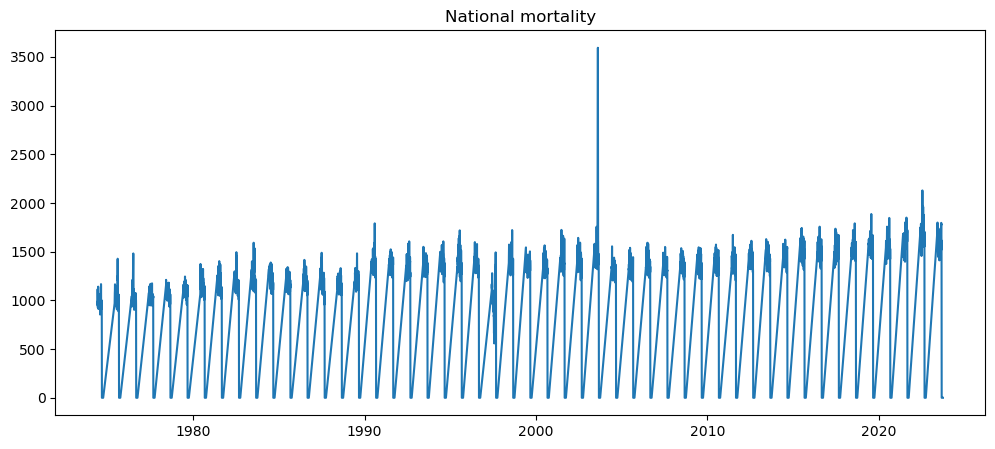

In [20]:
grouped_df = df_pp.groupby('date_deces').size().reset_index(name='count')
date_range = pd.date_range(start='1974-06-01', end='2023-09-30', freq='D')
date_range = date_range[date_range.month.isin([6, 7, 8, 9])]  # Keep only summer months

# Create a complete DataFrame with all dates
complete_df = pd.DataFrame({'date_deces': date_range})

# Merge with the grouped count, filling missing counts with 0
final_df = complete_df.merge(grouped_df, on='date_deces', how='left').fillna(0)
# Ensure count is integer
final_df['count'] = final_df['count'].astype(int)
plt.figure(figsize=(12,5))
plt.plot(final_df['date_deces'], final_df['count'])
plt.title("National mortality")

In [21]:
final_df

,date_deces,count
0,1974-06-01,974
1,1974-06-02,963
2,1974-06-03,975
3,1974-06-04,1115
4,1974-06-05,1045
...,...,...
6095,2023-09-26,0
6096,2023-09-27,0
6097,2023-09-28,0
6098,2023-09-29,0


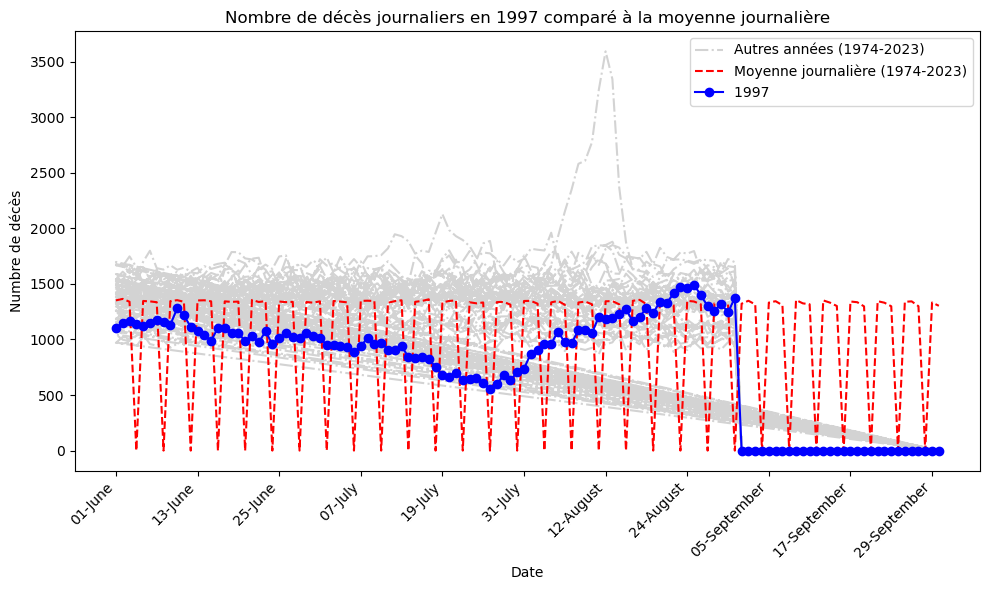

In [22]:
df_1997 = final_df[final_df['date_deces'].dt.year == 1997]
df_other_years = final_df[final_df['date_deces'].dt.year != 1997]
daily_mean = df_other_years.groupby(df_other_years['date_deces'].dt.date)['count'].mean()

final_df['day_month'] = final_df['date_deces'].dt.strftime('%d-%m')
daily_mean = final_df.groupby('day_month')['count'].mean()

plt.figure(figsize=(10, 6))
# Plot count for 1997

plt.plot(df_other_years['date_deces'].dt.strftime('%d-%B'), df_other_years['count'], linestyle='-.', color='lightgrey', label='Autres années (1974-2023)')
# Plot daily mean count for other years
plt.plot(df_1997['date_deces'].dt.strftime('%d-%B'), daily_mean.values, label='Moyenne journalière (1974-2023)', color='r', linestyle='--')
plt.plot(df_1997['date_deces'].dt.strftime('%d-%B'), df_1997['count'], marker='o', label='1997 ', color='b')

# Title and labels
plt.title('Nombre de décès journaliers en 1997 comparé à la moyenne journalière')
plt.xlabel('Date')
plt.ylabel('Numbre de décès')
plt.xticks(rotation=45, ha='right')  # Rotate and align the labels to the right
plt.xticks(ticks=range(0, len(df_1997), len(df_1997)//10)) 
plt.tight_layout()
plt.legend()
plt.savefig("deces_1997.png")
plt.show()


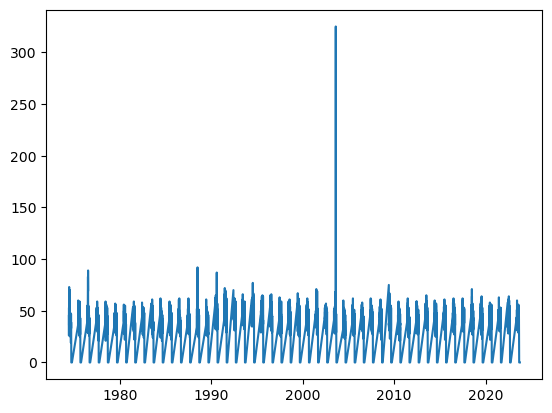

In [23]:
df_pp = df_pp[df_pp['code_insee_deces'] // 1000 == 75]

grouped_df = df_pp.groupby('date_deces').size().reset_index(name='count')
date_range = pd.date_range(start='1974-06-01', end='2023-09-30', freq='D')
date_range = date_range[date_range.month.isin([6, 7, 8, 9])]  # Keep only summer months

# Create a complete DataFrame with all dates
complete_df = pd.DataFrame({'date_deces': date_range})

# Merge with the grouped count, filling missing counts with 0
final_df = complete_df.merge(grouped_df, on='date_deces', how='left').fillna(0)
# Ensure count is integer
final_df['count'] = final_df['count'].astype(int)
plt.plot(final_df['date_deces'], final_df['count'])

In [24]:
ts_mort = np.array(final_df['count'])
mort_yearly = np.copy(ts_mort.reshape((50, 92)))

ValueError: cannot reshape array of size 6100 into shape (50,92)

In [ ]:
for year in range(50):
    plt.plot(mort_yearly[year, :], color="lightgrey")

plt.plot(np.arange(0,92), np.mean(mort_yearly, axis=(0)), ls="dashed", color="black")

In [ ]:
plt.bar(np.arange(1974,2024), np.sum(mort_yearly, axis=1))

In [ ]:
len(ts_mort)

In [ ]:
np.save("mortality_4.npy", ts_mort)

In [ ]:
df_old =  df_pp[df_pp["age"] >= 75]
grouped_df = df_old.groupby('date_deces').size().reset_index(name='count')
date_range = pd.date_range(start='1974-06-01', end='2023-08-31', freq='D')
date_range = date_range[date_range.month.isin([6, 7, 8])]  # Keep only summer months

# Create a complete DataFrame with all dates
complete_df = pd.DataFrame({'date_deces': date_range})

# Merge with the grouped count, filling missing counts with 0
final_df = complete_df.merge(grouped_df, on='date_deces', how='left').fillna(0)
# Ensure count is integer
final_df['count'] = final_df['count'].astype(int)
plt.plot(final_df['date_deces'], final_df['count'])

In [ ]:
ts_mort_old = np.array(final_df['count'])
mort_yearly_old = np.copy(ts_mort_old.reshape((50, 92)))
np.save("mortality_old.npy", ts_mort_old)
for year in range(50):
    plt.plot(mort_yearly_old[year, :], color="lightgrey")

plt.plot(np.arange(0,92), np.mean(mort_yearly_old, axis=(0)), ls="dashed", color="black")


In [ ]:
df_pp

In [ ]:
# Filter data for the years 1990, 2003, and 2010
df_pp['year_deces'] = df_pp['date_deces'].dt.year
selected_years = [2003]
df_filtered = df_pp[df_pp['year_deces'].isin(selected_years)]

# Plot the age distribution with year in the legend
plt.figure(figsize=(10, 6))
sns.histplot(data=df_filtered, x='age', hue='year_deces', kde=True, bins=100, palette='Set1')

plt.title('Age Distribution at Death')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.legend(title='Year of Death', labels=[str(year) for year in selected_years])
plt.show()

In [ ]:
selected_years = [1990, 2003, 2010]
df_filtered = df_pp[df_pp['year_deces'].isin(selected_years)]

# Plot the age distribution with year in the legend
plt.figure(figsize=(10, 6))
sns.histplot(data=df_filtered, x='age', hue='year_deces', kde=True, bins=100, palette='Set1', multiple="layer")

plt.title('Age Distribution at Death')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.legend(title='Year of Death', labels=[str(year) for year in selected_years[::-1]])
plt.show()

In [ ]:
df_97 = pd.read_csv("deces-1997.txt", sep=" ", header=None, names=["Nom", "Lieu", "Pays", "Code", "Bin", "code2"])